# NB01 — Data Exploration & Preprocessing
**FSDF-UCA-Net: Kidney Tumor Segmentation on KiTS19**

This notebook performs:
1. Dataset loading and exploration
2. Voxel spacing analysis and resampling target selection
3. Data-driven HU clipping (foreground percentile method)
4. Z-score normalization parameter computation
5. Volume preprocessing and saving
6. Dataset quality analysis (flagging known problematic cases)
7. 3-fold cross-validation split generation
8. Comprehensive visualizations

**Dataset:** KiTS19 — 210 contrast-enhanced CT scans with kidney + tumor annotations  
**References:**  
- Heller et al., "The KiTS19 Challenge Data" (arXiv:1904.00445)  
- Isensee & Maier-Hein, "An attempt at beating the 3D U-Net" (MICCAI 2019)

In [1]:
import numpy as np
import nibabel as nib
from pathlib import Path
from scipy.ndimage import zoom
import json, time, warnings
warnings.filterwarnings('ignore')

import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.colors as mcolors

print("Libraries loaded.")

Libraries loaded.


In [2]:
# ======== PATHS ========
DATA_ROOT = Path(r"D:\fsdf_uca_kits\kits19\data")
OUTPUT_DIR = Path(r"D:\fsdf_uca_kits\outputs")
PREPROC_DIR = OUTPUT_DIR / "preprocessed"
FIG_DIR = OUTPUT_DIR / "figures" / "nb01"
STATS_DIR = OUTPUT_DIR / "stats"

for d in [PREPROC_DIR, FIG_DIR, STATS_DIR]:
    d.mkdir(parents=True, exist_ok=True)

# ======== DATASET CONFIG ========
TOTAL_CASES = 210  # public KiTS19 training set

# Known problematic cases (documented in literature)
# Case 15: GitHub issue #21 (neheller/kits19), tagged "Label Error" by dataset creator
#          Kidney label extends beyond kidney region
# Case 37: Confirmed faulty by challenge organizers (MICCAI 2019 proceedings)
CONFIRMED_FAULTY = [15, 37]

# Cases flagged due to annotation disagreements (not organizer-confirmed)
ADDITIONAL_FLAGGED = [23, 68, 125, 133]

ALL_FLAGGED = CONFIRMED_FAULTY + ADDITIONAL_FLAGGED

print(f"Data root: {DATA_ROOT}")
print(f"Total cases: {TOTAL_CASES}")
print(f"Confirmed faulty (excluded from training): {CONFIRMED_FAULTY}")
print(f"Additionally flagged (reported only): {ADDITIONAL_FLAGGED}")

Data root: D:\fsdf_uca_kits\kits19\data
Total cases: 210
Confirmed faulty (excluded from training): [15, 37]
Additionally flagged (reported only): [23, 68, 125, 133]


## 1. Dataset Discovery & Integrity Check

In [3]:
case_dirs = []
missing = []
for i in range(TOTAL_CASES):
    case_dir = DATA_ROOT / f"case_{i:05d}"
    img_path = case_dir / "imaging.nii.gz"
    seg_path = case_dir / "segmentation.nii.gz"
    if img_path.exists() and seg_path.exists():
        case_dirs.append({
            'case_id': i,
            'case_name': f'case_{i:05d}',
            'img_path': str(img_path),
            'seg_path': str(seg_path),
            'is_faulty': i in CONFIRMED_FAULTY,
            'is_flagged': i in ALL_FLAGGED,
        })
    else:
        missing.append(i)

print(f"Found: {len(case_dirs)} / {TOTAL_CASES} cases")
if missing:
    print(f"MISSING: {missing}")
else:
    print("All cases present.")

train_eligible = [c for c in case_dirs if not c['is_faulty']]
print(f"Training-eligible: {len(train_eligible)} (excluded {len(CONFIRMED_FAULTY)} faulty)")

Found: 210 / 210 cases
All cases present.
Training-eligible: 208 (excluded 2 faulty)


## 2. Scan All Cases — Collect Statistics
Loads every case to collect voxel spacing, volume shape, class distribution,
and foreground HU values for preprocessing parameter computation.

**Runtime:** ~10-15 minutes

In [4]:
print("Scanning all cases for statistics...")
print(f"This reads all {len(case_dirs)} volumes once.\n")

all_stats = []
all_fg_hu = []
t0 = time.time()

for idx, case in enumerate(case_dirs):
    cid = case['case_id']

    img_nii = nib.load(case['img_path'])
    seg_nii = nib.load(case['seg_path'])

    img = img_nii.get_fdata().astype(np.float32)
    seg = seg_nii.get_fdata().astype(np.uint8)

    # Spacing: compute from affine matrix (robust for all NIfTI orientations)
    # nib.affines.voxel_sizes computes L2 norm of each affine column
    spacing = np.array(nib.affines.voxel_sizes(img_nii.affine), dtype=np.float32)
    spacing = np.maximum(spacing, 0.01)  # guard against zeros

    # Class counts
    n_bg = int((seg == 0).sum())
    n_kid = int((seg == 1).sum())
    n_tum = int((seg == 2).sum())
    total_vox = seg.size
    has_tumor = n_tum > 0

    # Foreground HU sampling (kidney + tumor regions)
    fg_mask = seg >= 1
    if fg_mask.any():
        fg_values = img[fg_mask]
        # Subsample for memory (50000 per case for accurate percentiles)
        if len(fg_values) > 50000:
            rng = np.random.RandomState(cid)
            fg_values = rng.choice(fg_values, 50000, replace=False)
        all_fg_hu.append(fg_values)

    stat = {
        'case_id': cid,
        'case_name': case['case_name'],
        'shape': list(img.shape),
        'spacing': [float(s) for s in spacing],
        'n_bg': n_bg,
        'n_kidney': n_kid,
        'n_tumor': n_tum,
        'total_voxels': total_vox,
        'kidney_pct': n_kid / total_vox * 100,
        'tumor_pct': n_tum / total_vox * 100,
        'has_tumor': has_tumor,
        'is_faulty': case['is_faulty'],
        'is_flagged': case['is_flagged'],
        'hu_min': float(img.min()),
        'hu_max': float(img.max()),
    }
    all_stats.append(stat)

    del img, seg, img_nii, seg_nii

    if (idx + 1) % 20 == 0 or idx == 0:
        et = time.time() - t0
        print(f"  [{idx+1}/{len(case_dirs)}] {case['case_name']} "
              f"shape={stat['shape']} spacing=[{spacing[0]:.2f}, {spacing[1]:.3f}, {spacing[2]:.3f}] "
              f"tumor={stat['tumor_pct']:.2f}% ({et:.0f}s)")

print(f"\nDone in {(time.time()-t0)/60:.1f} min")
print(f"Collected {len(all_stats)} case statistics")

Scanning all cases for statistics...
This reads all 210 volumes once.

  [1/210] case_00000 shape=[611, 512, 512] spacing=[0.50, 0.920, 0.920] tumor=0.01% (5s)
  [20/210] case_00019 shape=[129, 512, 512] spacing=[3.75, 0.938, 0.938] tumor=0.00% (37s)
  [40/210] case_00039 shape=[90, 512, 512] spacing=[5.00, 0.703, 0.703] tumor=0.02% (67s)
  [60/210] case_00059 shape=[738, 512, 512] spacing=[0.50, 0.789, 0.789] tumor=0.03% (104s)
  [80/210] case_00079 shape=[124, 512, 512] spacing=[5.00, 0.645, 0.645] tumor=0.59% (138s)
  [100/210] case_00099 shape=[105, 512, 512] spacing=[5.00, 0.707, 0.707] tumor=0.16% (174s)
  [120/210] case_00119 shape=[91, 512, 512] spacing=[5.00, 0.762, 0.762] tumor=0.20% (225s)
  [140/210] case_00139 shape=[103, 512, 512] spacing=[5.00, 0.801, 0.801] tumor=1.13% (255s)
  [160/210] case_00159 shape=[719, 512, 512] spacing=[0.50, 0.766, 0.766] tumor=0.14% (323s)
  [180/210] case_00179 shape=[99, 512, 512] spacing=[5.00, 0.742, 0.742] tumor=0.21% (351s)
  [200/210] 

## 3. Compute Preprocessing Parameters

In [5]:
# 1. Target spacing (median across dataset)
all_spacings = np.array([s['spacing'] for s in all_stats])
median_spacing = np.median(all_spacings, axis=0)
print("Voxel Spacing Analysis:")
print(f"  Median:  [{median_spacing[0]:.2f}, {median_spacing[1]:.4f}, {median_spacing[2]:.4f}] mm")
print(f"  Min:     [{all_spacings.min(axis=0)[0]:.2f}, {all_spacings.min(axis=0)[1]:.4f}, {all_spacings.min(axis=0)[2]:.4f}] mm")
print(f"  Max:     [{all_spacings.max(axis=0)[0]:.2f}, {all_spacings.max(axis=0)[1]:.4f}, {all_spacings.max(axis=0)[2]:.4f}] mm")

TARGET_SPACING = [float(s) for s in median_spacing]
print(f"\nTarget spacing: {[f'{s:.4f}' for s in TARGET_SPACING]} mm")

# 2. HU clipping (foreground percentiles)
all_fg = np.concatenate(all_fg_hu)
hu_p05 = float(np.percentile(all_fg, 0.5))
hu_p995 = float(np.percentile(all_fg, 99.5))
print(f"\nHU Clipping (foreground 0.5th / 99.5th percentile):")
print(f"  Range: [{hu_p05:.1f}, {hu_p995:.1f}]")

HU_CLIP_LOW = float(np.round(hu_p05))
HU_CLIP_HIGH = float(np.round(hu_p995))
print(f"  Rounded: [{HU_CLIP_LOW}, {HU_CLIP_HIGH}]")

# 3. Z-score parameters
clipped_fg = np.clip(all_fg, HU_CLIP_LOW, HU_CLIP_HIGH)
FG_MEAN = float(np.mean(clipped_fg))
FG_STD = float(np.std(clipped_fg))
print(f"\nZ-score Normalization:")
print(f"  Mean: {FG_MEAN:.2f}")
print(f"  Std:  {FG_STD:.2f}")

del all_fg, all_fg_hu, clipped_fg

# Save
preproc_params = {
    'target_spacing': TARGET_SPACING,
    'hu_clip_low': HU_CLIP_LOW,
    'hu_clip_high': HU_CLIP_HIGH,
    'foreground_mean': FG_MEAN,
    'foreground_std': FG_STD,
    'confirmed_faulty_cases': CONFIRMED_FAULTY,
    'additional_flagged_cases': ADDITIONAL_FLAGGED,
}
with open(STATS_DIR / 'preproc_params.json', 'w') as f:
    json.dump(preproc_params, f, indent=2)

print(f"\nSaved: {STATS_DIR / 'preproc_params.json'}")

Voxel Spacing Analysis:
  Median:  [3.00, 0.7812, 0.7812] mm
  Min:     [0.50, 0.4375, 0.4375] mm
  Max:     [5.00, 1.0410, 1.0410] mm

Target spacing: ['3.0000', '0.7812', '0.7812'] mm

HU Clipping (foreground 0.5th / 99.5th percentile):
  Range: [-75.0, 295.0]
  Rounded: [-75.0, 295.0]

Z-score Normalization:
  Mean: 102.43
  Std:  71.96

Saved: D:\fsdf_uca_kits\outputs\stats\preproc_params.json


## 4. Visualizations

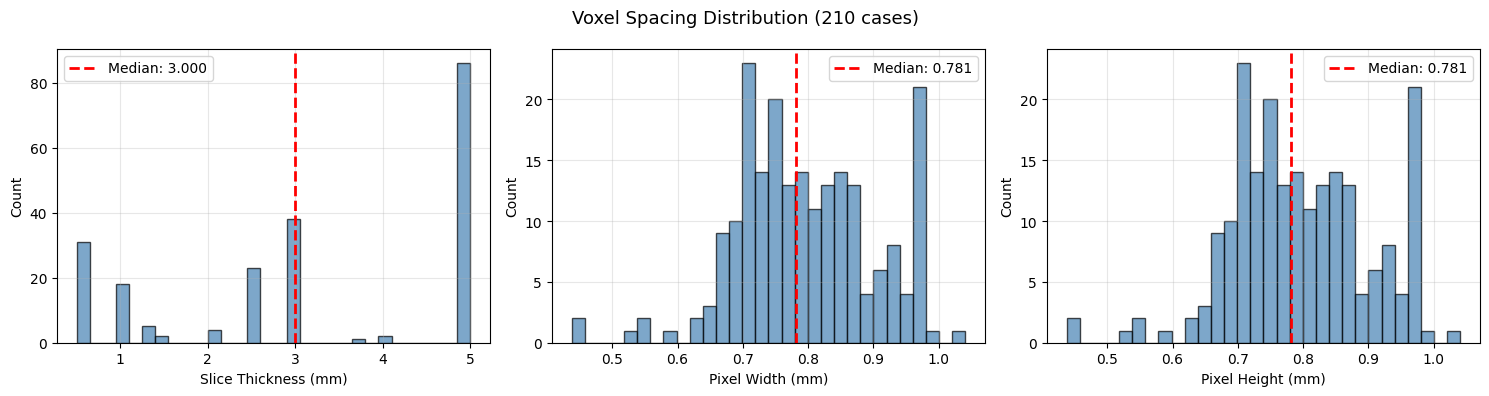

In [6]:
# ======== Plot 1: Voxel Spacing Distribution ========
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
labels = ['Slice Thickness (mm)', 'Pixel Width (mm)', 'Pixel Height (mm)']

for i in range(3):
    vals = all_spacings[:, i]
    axes[i].hist(vals, bins=30, color='steelblue', edgecolor='black', alpha=0.7)
    axes[i].axvline(median_spacing[i], color='red', ls='--', lw=2,
                    label=f'Median: {median_spacing[i]:.3f}')
    axes[i].set_xlabel(labels[i])
    axes[i].set_ylabel('Count')
    axes[i].legend()
    axes[i].grid(True, alpha=0.3)

plt.suptitle('Voxel Spacing Distribution (210 cases)', fontsize=13)
plt.tight_layout()
plt.savefig(FIG_DIR / 'spacing_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

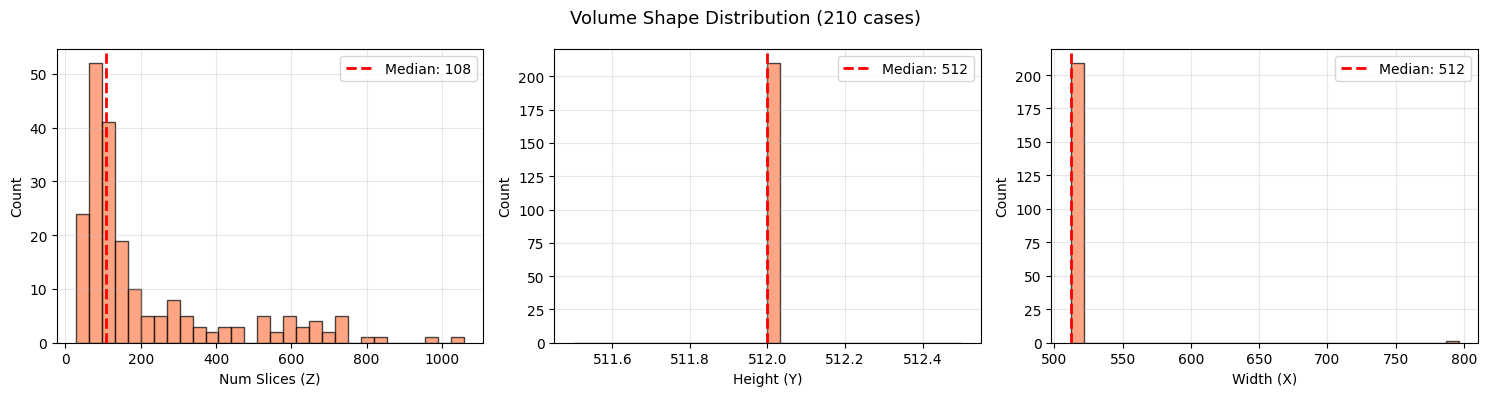

In [7]:
# ======== Plot 2: Volume Shape Distribution ========
shapes = np.array([s['shape'] for s in all_stats])

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
dim_labels = ['Num Slices (Z)', 'Height (Y)', 'Width (X)']

for i in range(3):
    axes[i].hist(shapes[:, i], bins=30, color='coral', edgecolor='black', alpha=0.7)
    axes[i].axvline(np.median(shapes[:, i]), color='red', ls='--', lw=2,
                    label=f'Median: {np.median(shapes[:, i]):.0f}')
    axes[i].set_xlabel(dim_labels[i])
    axes[i].set_ylabel('Count')
    axes[i].legend()
    axes[i].grid(True, alpha=0.3)

plt.suptitle('Volume Shape Distribution (210 cases)', fontsize=13)
plt.tight_layout()
plt.savefig(FIG_DIR / 'shape_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

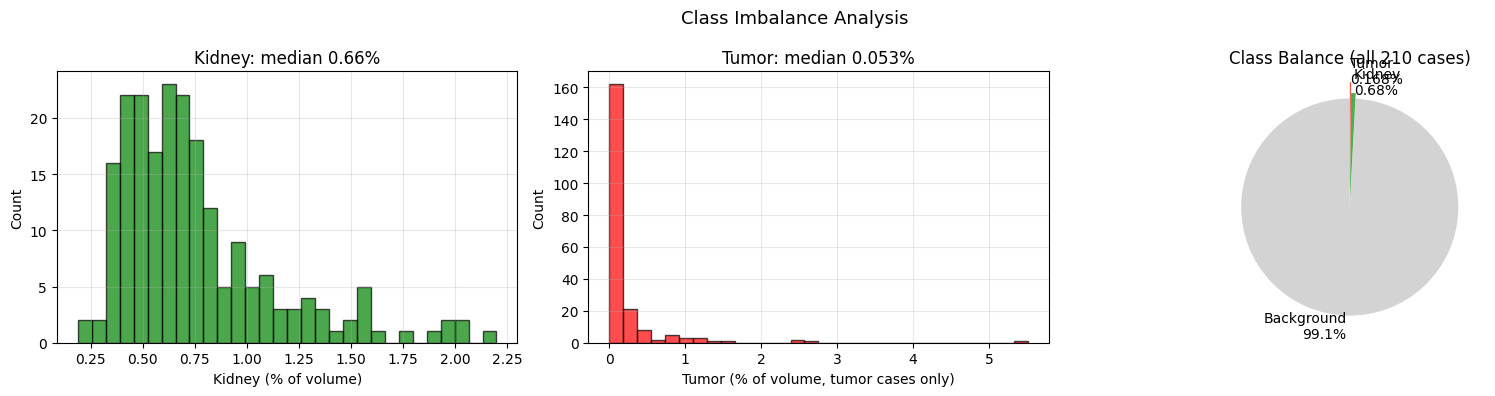

Total voxels: 11,944,271,872
Background: 99.15%
Kidney:     0.684%
Tumor:      0.1680%
Cases with tumor: 210 / 210


In [8]:
# ======== Plot 3: Class Imbalance ========
kid_pcts = [s['kidney_pct'] for s in all_stats]
tum_pcts = [s['tumor_pct'] for s in all_stats]
has_tumor = [s['has_tumor'] for s in all_stats]

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].hist(kid_pcts, bins=30, color='green', edgecolor='black', alpha=0.7)
axes[0].set_xlabel('Kidney (% of volume)')
axes[0].set_ylabel('Count')
axes[0].set_title(f'Kidney: median {np.median(kid_pcts):.2f}%')
axes[0].grid(True, alpha=0.3)

tum_nonzero = [t for t in tum_pcts if t > 0]
axes[1].hist(tum_nonzero, bins=30, color='red', edgecolor='black', alpha=0.7)
axes[1].set_xlabel('Tumor (% of volume, tumor cases only)')
axes[1].set_ylabel('Count')
axes[1].set_title(f'Tumor: median {np.median(tum_nonzero):.3f}%')
axes[1].grid(True, alpha=0.3)

total_bg = sum(s['n_bg'] for s in all_stats)
total_kid = sum(s['n_kidney'] for s in all_stats)
total_tum = sum(s['n_tumor'] for s in all_stats)
total = total_bg + total_kid + total_tum

sizes = [total_bg/total*100, total_kid/total*100, total_tum/total*100]
labels_pie = [
    f'Background\n{sizes[0]:.1f}%',
    f'Kidney\n{sizes[1]:.2f}%',
    f'Tumor\n{sizes[2]:.3f}%',
]
colors = ['lightgray', '#4CAF50', '#F44336']
explode = (0, 0.05, 0.15)
axes[2].pie(sizes, labels=labels_pie, colors=colors, explode=explode,
            autopct='', startangle=90)
axes[2].set_title('Class Balance (all 210 cases)')

plt.suptitle('Class Imbalance Analysis', fontsize=13)
plt.tight_layout()
plt.savefig(FIG_DIR / 'class_imbalance.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"Total voxels: {total:,}")
print(f"Background: {total_bg/total*100:.2f}%")
print(f"Kidney:     {total_kid/total*100:.3f}%")
print(f"Tumor:      {total_tum/total*100:.4f}%")
print(f"Cases with tumor: {sum(has_tumor)} / {len(has_tumor)}")

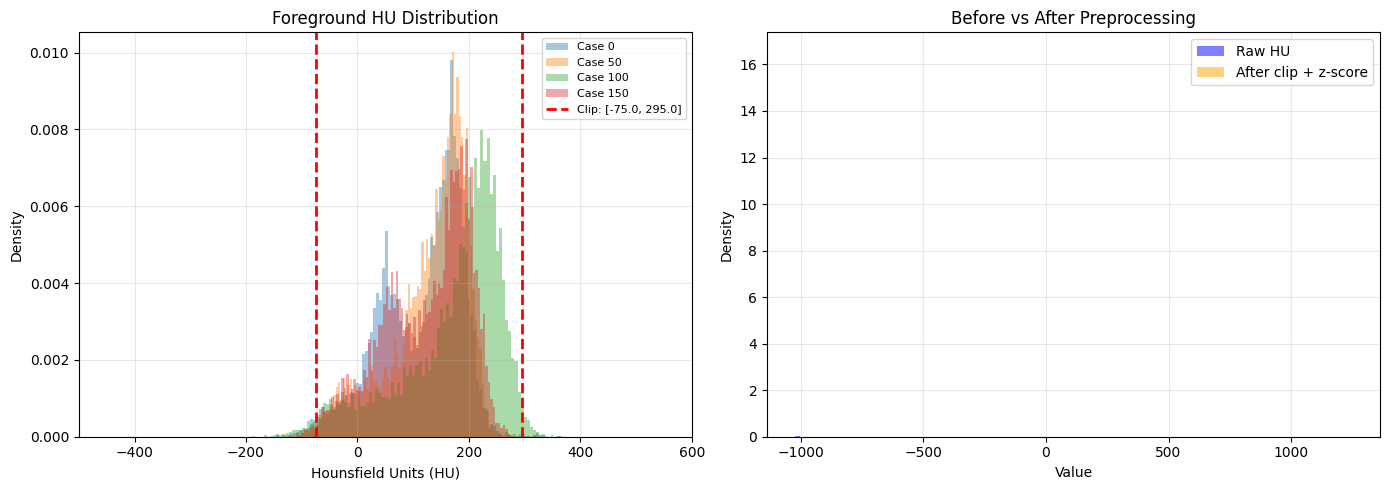

In [9]:
# ======== Plot 4: HU Distribution & Clipping ========
sample_cases = [0, 50, 100, 150]
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for cid in sample_cases:
    case = case_dirs[cid]
    img = nib.load(case['img_path']).get_fdata().astype(np.float32)
    seg = nib.load(case['seg_path']).get_fdata().astype(np.uint8)
    fg = img[seg >= 1]
    if len(fg) > 10000:
        fg = np.random.choice(fg, 10000, replace=False)
    axes[0].hist(fg, bins=100, alpha=0.4, density=True,
                 label=f'Case {cid}')
    del img, seg

axes[0].axvline(HU_CLIP_LOW, color='red', ls='--', lw=2, label=f'Clip: [{HU_CLIP_LOW}, {HU_CLIP_HIGH}]')
axes[0].axvline(HU_CLIP_HIGH, color='red', ls='--', lw=2)
axes[0].set_xlabel('Hounsfield Units (HU)')
axes[0].set_ylabel('Density')
axes[0].set_title('Foreground HU Distribution')
axes[0].legend(fontsize=8)
axes[0].grid(True, alpha=0.3)
axes[0].set_xlim(-500, 600)

img_raw = nib.load(case_dirs[0]['img_path']).get_fdata().astype(np.float32)
mid_slice = img_raw.shape[0] // 2
raw_slice = img_raw[mid_slice]
processed = np.clip(raw_slice, HU_CLIP_LOW, HU_CLIP_HIGH)
processed = (processed - FG_MEAN) / FG_STD

axes[1].hist(raw_slice.flatten(), bins=100, alpha=0.5, density=True,
             label='Raw HU', color='blue')
axes[1].hist(processed.flatten(), bins=100, alpha=0.5, density=True,
             label='After clip + z-score', color='orange')
axes[1].set_xlabel('Value')
axes[1].set_ylabel('Density')
axes[1].set_title('Before vs After Preprocessing')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

del img_raw
plt.tight_layout()
plt.savefig(FIG_DIR / 'hu_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

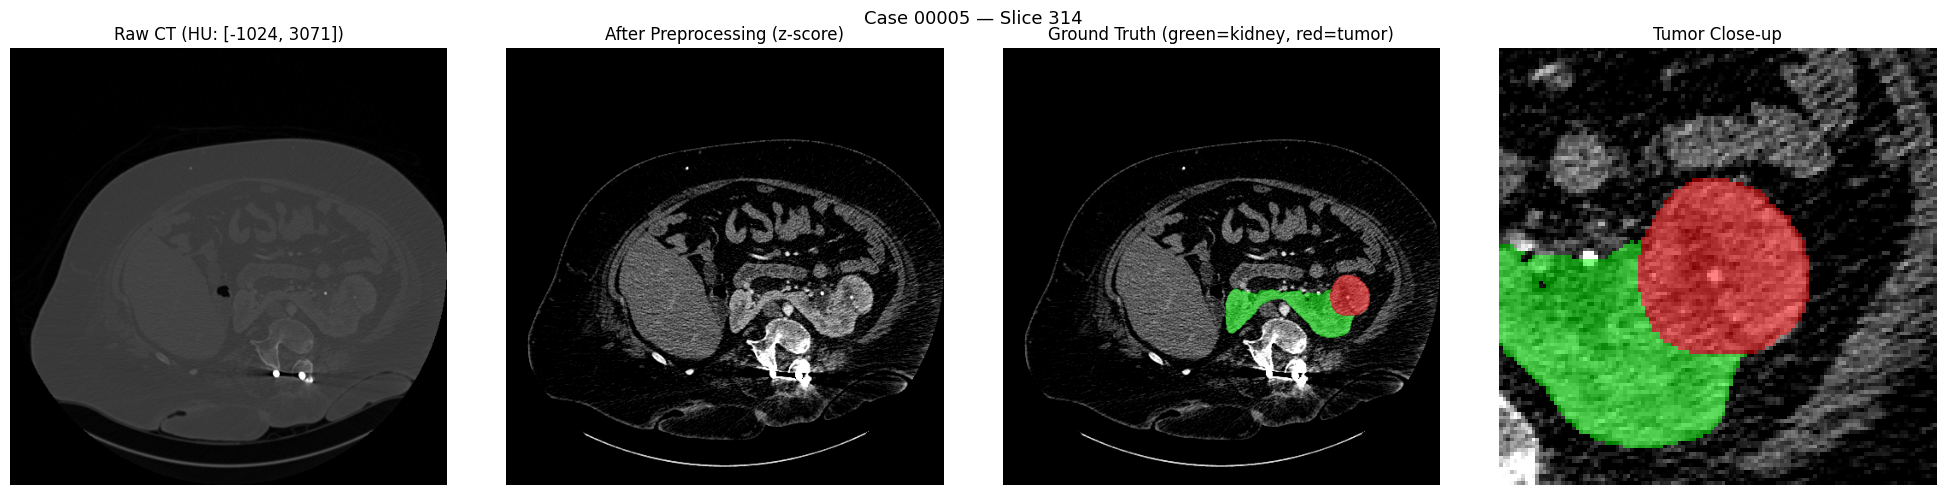

In [10]:
# ======== Plot 5: Example CT Slices ========
sample_case_id = 5
case = case_dirs[sample_case_id]
img = nib.load(case['img_path']).get_fdata().astype(np.float32)
seg = nib.load(case['seg_path']).get_fdata().astype(np.uint8)

tumor_per_slice = [(seg[s] == 2).sum() for s in range(seg.shape[0])]
best_slice = int(np.argmax(tumor_per_slice))

raw = img[best_slice]
gt = seg[best_slice]
preprocessed = np.clip(raw, HU_CLIP_LOW, HU_CLIP_HIGH)
preprocessed = (preprocessed - FG_MEAN) / FG_STD

fig, axes = plt.subplots(1, 4, figsize=(20, 5))
seg_cmap = mcolors.ListedColormap(['black', '#00FF00', '#FF0000'])

axes[0].imshow(raw, cmap='gray')
axes[0].set_title(f'Raw CT (HU: [{raw.min():.0f}, {raw.max():.0f}])')
axes[0].axis('off')

axes[1].imshow(preprocessed, cmap='gray')
axes[1].set_title('After Preprocessing (z-score)')
axes[1].axis('off')

axes[2].imshow(preprocessed, cmap='gray')
gt_masked = np.ma.masked_where(gt == 0, gt)
axes[2].imshow(gt_masked, cmap=seg_cmap, alpha=0.5, vmin=0, vmax=2)
axes[2].set_title('Ground Truth (green=kidney, red=tumor)')
axes[2].axis('off')

tumor_coords = np.argwhere(gt == 2)
if len(tumor_coords) > 0:
    cy, cx = tumor_coords.mean(axis=0).astype(int)
    pad = 60
    y0, y1 = max(0, cy-pad), min(raw.shape[0], cy+pad)
    x0, x1 = max(0, cx-pad), min(raw.shape[1], cx+pad)
    axes[3].imshow(preprocessed[y0:y1, x0:x1], cmap='gray')
    gt_crop = np.ma.masked_where(gt[y0:y1, x0:x1] == 0, gt[y0:y1, x0:x1])
    axes[3].imshow(gt_crop, cmap=seg_cmap, alpha=0.5, vmin=0, vmax=2)
    axes[3].set_title('Tumor Close-up')
else:
    axes[3].set_title('No tumor in this slice')
axes[3].axis('off')

plt.suptitle(f'Case {sample_case_id:05d} — Slice {best_slice}', fontsize=13)
plt.tight_layout()
plt.savefig(FIG_DIR / 'example_slices.png', dpi=150, bbox_inches='tight')
plt.show()
del img, seg

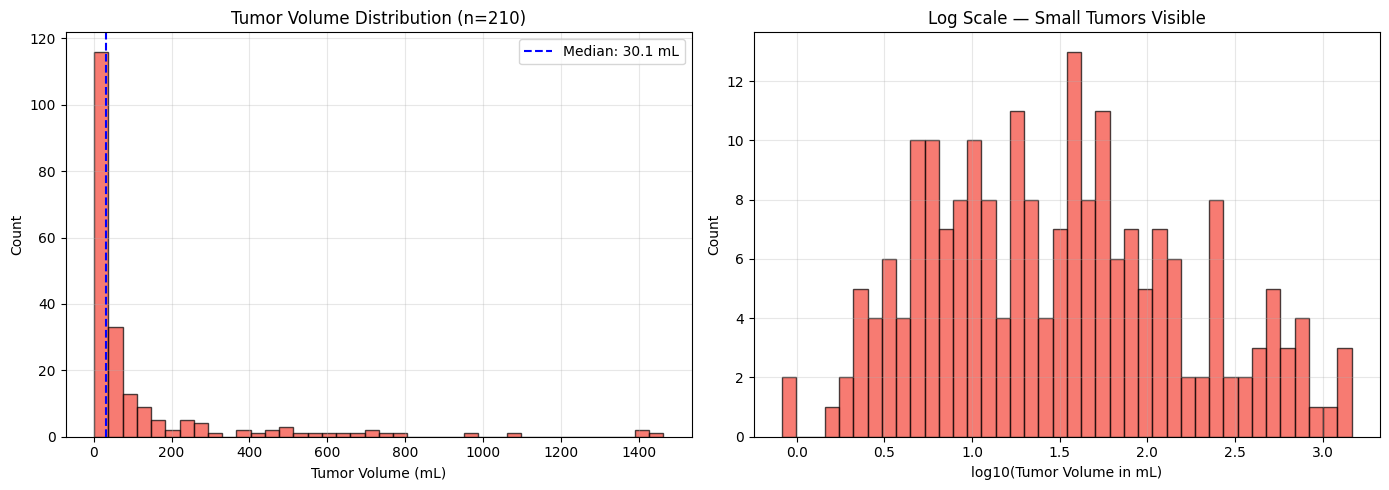

Tumor cases: 210
Volume range: 0.82 — 1463.8 mL
Median: 30.1 mL
Small tumors (<1 mL): 2
Large tumors (>100 mL): 51


In [11]:
# ======== Plot 6: Tumor Size Distribution ========
tumor_vols = []
for s in all_stats:
    if s['n_tumor'] > 0:
        voxel_vol = np.prod(s['spacing'])
        tumor_ml = s['n_tumor'] * voxel_vol / 1000
        tumor_vols.append(tumor_ml)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(tumor_vols, bins=40, color='#F44336', edgecolor='black', alpha=0.7)
axes[0].set_xlabel('Tumor Volume (mL)')
axes[0].set_ylabel('Count')
axes[0].set_title(f'Tumor Volume Distribution (n={len(tumor_vols)})')
axes[0].axvline(np.median(tumor_vols), color='blue', ls='--',
                label=f'Median: {np.median(tumor_vols):.1f} mL')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].hist(np.log10(np.array(tumor_vols) + 0.01), bins=40,
             color='#F44336', edgecolor='black', alpha=0.7)
axes[1].set_xlabel('log10(Tumor Volume in mL)')
axes[1].set_ylabel('Count')
axes[1].set_title('Log Scale — Small Tumors Visible')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(FIG_DIR / 'tumor_size_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"Tumor cases: {len(tumor_vols)}")
print(f"Volume range: {min(tumor_vols):.2f} — {max(tumor_vols):.1f} mL")
print(f"Median: {np.median(tumor_vols):.1f} mL")
print(f"Small tumors (<1 mL): {sum(1 for v in tumor_vols if v < 1)}")
print(f"Large tumors (>100 mL): {sum(1 for v in tumor_vols if v > 100)}")

In [12]:
# ======== Dataset Quality Summary ========
print("=" * 60)
print("DATASET QUALITY ANALYSIS")
print("=" * 60)

print(f"\nConfirmed faulty (excluded from training):")
for cid in CONFIRMED_FAULTY:
    s = next(st for st in all_stats if st['case_id'] == cid)
    print(f"  Case {cid:05d}: shape={s['shape']}, "
          f"tumor={s['n_tumor']} voxels ({s['tumor_pct']:.3f}%)")
    if cid == 15:
        print(f"    Source: GitHub issue #21 (neheller/kits19), Label Error tag")
    if cid == 37:
        print(f"    Source: Confirmed by challenge organizers (MICCAI 2019)")

print(f"\nAdditionally flagged (reported only, not excluded):")
for cid in ADDITIONAL_FLAGGED:
    s = next(st for st in all_stats if st['case_id'] == cid)
    print(f"  Case {cid:05d}: shape={s['shape']}, "
          f"tumor={s['n_tumor']} voxels ({s['tumor_pct']:.3f}%)")

DATASET QUALITY ANALYSIS

Confirmed faulty (excluded from training):
  Case 00015: shape=[75, 512, 512], tumor=11562 voxels (0.059%)
    Source: GitHub issue #21 (neheller/kits19), Label Error tag
  Case 00037: shape=[97, 512, 512], tumor=96532 voxels (0.380%)
    Source: Confirmed by challenge organizers (MICCAI 2019)

Additionally flagged (reported only, not excluded):
  Case 00023: shape=[107, 512, 512], tumor=952 voxels (0.003%)
  Case 00068: shape=[626, 512, 512], tumor=78868 voxels (0.048%)
  Case 00125: shape=[171, 512, 512], tumor=2473 voxels (0.006%)
  Case 00133: shape=[186, 512, 512], tumor=35225 voxels (0.072%)


## 5. Preprocess & Save All Volumes
For each case:
1. Resample to target spacing (cubic for image, nearest for labels)
2. Clip HU to computed range
3. Z-score normalize
4. Save as .npy

**Runtime:** ~20-30 minutes

**Important:** Delete `outputs/preprocessed/` if re-running after parameter changes.

In [13]:
def resample_volume(img, seg, original_spacing, target_spacing):
    """Resample image and segmentation to target spacing."""
    original_spacing = np.array(original_spacing)
    target_spacing = np.array(target_spacing)
    zoom_factors = original_spacing / target_spacing

    if np.allclose(zoom_factors, 1.0, atol=0.05):
        return img, seg

    img_rs = zoom(img, zoom_factors, order=3, mode='nearest')
    seg_rs = zoom(seg.astype(np.float32), zoom_factors, order=0, mode='nearest')
    seg_rs = np.round(seg_rs).astype(np.uint8)

    return img_rs.astype(np.float32), seg_rs


def preprocess_volume(img, hu_low, hu_high, mean, std):
    """Clip HU and z-score normalize."""
    img = np.clip(img, hu_low, hu_high)
    img = (img - mean) / std
    return img.astype(np.float32)


print("Preprocessing functions ready.")
print(f"Target spacing: {[f'{s:.4f}' for s in TARGET_SPACING]} mm")
print(f"HU clip: [{HU_CLIP_LOW}, {HU_CLIP_HIGH}]")
print(f"Z-score: mean={FG_MEAN:.2f}, std={FG_STD:.2f}")

Preprocessing functions ready.
Target spacing: ['3.0000', '0.7812', '0.7812'] mm
HU clip: [-75.0, 295.0]
Z-score: mean=102.43, std=71.96


In [14]:
print("Preprocessing all volumes...\n")

t0 = time.time()
preproc_meta = []

for idx, case in enumerate(case_dirs):
    cid = case['case_id']
    case_name = case['case_name']

    img_nii = nib.load(case['img_path'])
    seg_nii = nib.load(case['seg_path'])
    img = img_nii.get_fdata().astype(np.float32)
    seg = seg_nii.get_fdata().astype(np.uint8)

    # Look up spacing by case_id (safe, no index assumptions)
    original_spacing = next(s for s in all_stats if s['case_id'] == cid)['spacing']
    original_shape = list(img.shape)

    # Resample
    img_rs, seg_rs = resample_volume(img, seg, original_spacing, TARGET_SPACING)

    # Preprocess
    img_pp = preprocess_volume(img_rs, HU_CLIP_LOW, HU_CLIP_HIGH, FG_MEAN, FG_STD)

    # Save
    case_out = PREPROC_DIR / case_name
    case_out.mkdir(parents=True, exist_ok=True)
    np.save(case_out / 'image.npy', img_pp)
    np.save(case_out / 'label.npy', seg_rs)

    meta = {
        'case_id': cid,
        'case_name': case_name,
        'original_shape': original_shape,
        'original_spacing': original_spacing,
        'resampled_shape': list(img_pp.shape),
        'target_spacing': TARGET_SPACING,
        'has_tumor': bool((seg_rs == 2).any()),
        'n_tumor_voxels': int((seg_rs == 2).sum()),
        'n_kidney_voxels': int((seg_rs == 1).sum()),
        'is_faulty': cid in CONFIRMED_FAULTY,
        'is_flagged': cid in ALL_FLAGGED,
        'exclude_from_training': cid in CONFIRMED_FAULTY,
    }
    preproc_meta.append(meta)

    with open(case_out / 'meta.json', 'w') as f:
        json.dump(meta, f, indent=2)

    del img, seg, img_nii, seg_nii, img_rs, seg_rs, img_pp

    if (idx + 1) % 20 == 0 or idx == 0:
        et = time.time() - t0
        print(f"  [{idx+1}/{len(case_dirs)}] {case_name} "
              f"{original_shape} -> {meta['resampled_shape']} ({et:.0f}s)")

with open(STATS_DIR / 'preproc_meta.json', 'w') as f:
    json.dump(preproc_meta, f, indent=2)

print(f"\nDone in {(time.time()-t0)/60:.1f} min")
print(f"Saved {len(preproc_meta)} preprocessed volumes to {PREPROC_DIR}")

Preprocessing all volumes...

  [1/210] case_00000 [611, 512, 512] -> [102, 603, 603] (19s)
  [20/210] case_00019 [129, 512, 512] -> [161, 614, 614] (179s)
  [40/210] case_00039 [90, 512, 512] -> [150, 461, 461] (386s)
  [60/210] case_00059 [738, 512, 512] -> [123, 517, 517] (629s)
  [80/210] case_00079 [124, 512, 512] -> [207, 422, 422] (828s)
  [100/210] case_00099 [105, 512, 512] -> [175, 463, 463] (1029s)
  [120/210] case_00119 [91, 512, 512] -> [152, 499, 499] (1220s)
  [140/210] case_00139 [103, 512, 512] -> [172, 525, 525] (1425s)
  [160/210] case_00159 [719, 512, 512] -> [120, 502, 502] (1675s)
  [180/210] case_00179 [99, 512, 512] -> [165, 486, 486] (1916s)
  [200/210] case_00199 [121, 512, 512] -> [101, 486, 486] (2143s)

Done in 37.6 min
Saved 210 preprocessed volumes to D:\fsdf_uca_kits\outputs\preprocessed


In [15]:
# ======== Verify Preprocessing ========
verify_ids = [0, 50, 100, 150, 200]
print("Preprocessing Verification:")
print(f"{'Case':<15} {'Orig Shape':<22} {'New Shape':<22} "
      f"{'Orig Spacing (mm)':<25} {'Target Spacing (mm)'}")
print("-" * 100)
for m in preproc_meta:
    if m['case_id'] in verify_ids:
        print(f"{m['case_name']:<15} "
              f"{str(m['original_shape']):<22} "
              f"{str(m['resampled_shape']):<22} "
              f"{str([round(s,4) for s in m['original_spacing']]):<25} "
              f"{[round(s,4) for s in TARGET_SPACING]}")

# Sanity check: load and verify
test_img = np.load(PREPROC_DIR / 'case_00000' / 'image.npy')
test_seg = np.load(PREPROC_DIR / 'case_00000' / 'label.npy')
print(f"\nSanity check (case_00000):")
print(f"  Image: shape={test_img.shape}, dtype={test_img.dtype}, "
      f"range=[{test_img.min():.2f}, {test_img.max():.2f}]")
print(f"  Label: shape={test_seg.shape}, dtype={test_seg.dtype}, "
      f"unique={np.unique(test_seg)}")
print(f"  Shapes match: {test_img.shape == test_seg.shape}")
del test_img, test_seg

Preprocessing Verification:
Case            Orig Shape             New Shape              Orig Spacing (mm)         Target Spacing (mm)
----------------------------------------------------------------------------------------------------
case_00000      [611, 512, 512]        [102, 603, 603]        [0.5, 0.9199, 0.9199]     [3.0, 0.7812, 0.7812]
case_00050      [96, 512, 512]         [80, 452, 452]         [2.5, 0.6895, 0.6895]     [3.0, 0.7812, 0.7812]
case_00100      [470, 512, 512]        [157, 540, 540]        [1.0, 0.8242, 0.8242]     [3.0, 0.7812, 0.7812]
case_00150      [106, 512, 512]        [88, 486, 486]         [2.5, 0.7422, 0.7422]     [3.0, 0.7812, 0.7812]
case_00200      [103, 512, 512]        [137, 486, 486]        [4.0, 0.7422, 0.7422]     [3.0, 0.7812, 0.7812]

Sanity check (case_00000):
  Image: shape=(102, 603, 603), dtype=float32, range=[-2.47, 2.68]
  Label: shape=(102, 603, 603), dtype=uint8, unique=[0 1 2]
  Shapes match: True


## 6. Cross-Validation Splits
3-fold CV on 208 training-eligible cases (excluding confirmed faulty cases 15, 37).  
All subsequent notebooks (NB02-NB05) must load `fold_splits.json` for consistent splits.

In [16]:
from sklearn.model_selection import KFold

eligible_cases = [
    m['case_name'] for m in preproc_meta
    if not m['exclude_from_training']
]
print(f"Training-eligible cases: {len(eligible_cases)}")

N_FOLDS = 3
kf = KFold(n_splits=N_FOLDS, shuffle=True, random_state=42)
eligible_array = np.array(eligible_cases)

fold_splits = {'n_folds': N_FOLDS, 'random_state': 42, 'folds': {}}
for fold_idx, (train_idx, val_idx) in enumerate(kf.split(eligible_array)):
    train_names = eligible_array[train_idx].tolist()
    val_names = eligible_array[val_idx].tolist()
    fold_splits['folds'][f'fold_{fold_idx}'] = {
        'train': train_names,
        'val': val_names,
    }
    val_set = set(val_names)
    n_val_tumor = sum(
        1 for m in preproc_meta
        if m['case_name'] in val_set and m['has_tumor']
    )
    print(f"  Fold {fold_idx}: {len(train_names)} train, {len(val_names)} val "
          f"({n_val_tumor} val cases with tumor)")

with open(STATS_DIR / 'fold_splits.json', 'w') as f:
    json.dump(fold_splits, f, indent=2)

print(f"\nSaved: {STATS_DIR / 'fold_splits.json'}")
print(f"All notebooks (NB02-NB05) load this file for consistent splits.")

Training-eligible cases: 208
  Fold 0: 138 train, 70 val (70 val cases with tumor)
  Fold 1: 139 train, 69 val (69 val cases with tumor)
  Fold 2: 139 train, 69 val (69 val cases with tumor)

Saved: D:\fsdf_uca_kits\outputs\stats\fold_splits.json
All notebooks (NB02-NB05) load this file for consistent splits.


## 7. Summary

In [17]:
print("\n" + "=" * 70)
print("NB01 SUMMARY")
print("=" * 70)

print(f"\nDataset: KiTS19 ({len(case_dirs)} cases)")
print(f"  With tumor: {sum(1 for s in all_stats if s['has_tumor'])}")
print(f"  Without tumor: {sum(1 for s in all_stats if not s['has_tumor'])}")

print(f"\nPreprocessing:")
print(f"  Target spacing:  {[f'{s:.4f}' for s in TARGET_SPACING]} mm")
print(f"  HU clip range:   [{HU_CLIP_LOW}, {HU_CLIP_HIGH}]")
print(f"  Z-score mean:    {FG_MEAN:.2f}")
print(f"  Z-score std:     {FG_STD:.2f}")

print(f"\nData Quality:")
print(f"  Excluded from training: cases {CONFIRMED_FAULTY} (confirmed faulty)")
print(f"  Additionally flagged:   cases {ADDITIONAL_FLAGGED} (reported only)")
print(f"  Training-eligible: {len(eligible_cases)} cases")

print(f"\nClass Balance:")
print(f"  Background: {total_bg/total*100:.2f}%")
print(f"  Kidney:     {total_kid/total*100:.3f}%")
print(f"  Tumor:      {total_tum/total*100:.4f}%")

print(f"\nCross-Validation: {N_FOLDS}-fold")
for fi in range(N_FOLDS):
    f = fold_splits['folds'][f'fold_{fi}']
    print(f"  Fold {fi}: {len(f['train'])} train, {len(f['val'])} val")

print(f"\nOutputs:")
print(f"  Preprocessed: {PREPROC_DIR}")
print(f"  Parameters:   {STATS_DIR / 'preproc_params.json'}")
print(f"  Fold splits:  {STATS_DIR / 'fold_splits.json'}")
print(f"  Metadata:     {STATS_DIR / 'preproc_meta.json'}")
print(f"  Statistics:   {STATS_DIR / 'dataset_stats.json'}")
print(f"  Figures:      {FIG_DIR}")

print(f"\n→ Next: NB02 (Stage 1 — 3D Kidney Localizer)")


NB01 SUMMARY

Dataset: KiTS19 (210 cases)
  With tumor: 210
  Without tumor: 0

Preprocessing:
  Target spacing:  ['3.0000', '0.7812', '0.7812'] mm
  HU clip range:   [-75.0, 295.0]
  Z-score mean:    102.43
  Z-score std:     71.96

Data Quality:
  Excluded from training: cases [15, 37] (confirmed faulty)
  Additionally flagged:   cases [23, 68, 125, 133] (reported only)
  Training-eligible: 208 cases

Class Balance:
  Background: 99.15%
  Kidney:     0.684%
  Tumor:      0.1680%

Cross-Validation: 3-fold
  Fold 0: 138 train, 70 val
  Fold 1: 139 train, 69 val
  Fold 2: 139 train, 69 val

Outputs:
  Preprocessed: D:\fsdf_uca_kits\outputs\preprocessed
  Parameters:   D:\fsdf_uca_kits\outputs\stats\preproc_params.json
  Fold splits:  D:\fsdf_uca_kits\outputs\stats\fold_splits.json
  Metadata:     D:\fsdf_uca_kits\outputs\stats\preproc_meta.json
  Statistics:   D:\fsdf_uca_kits\outputs\stats\dataset_stats.json
  Figures:      D:\fsdf_uca_kits\outputs\figures\nb01

→ Next: NB02 (Stage 1 

In [18]:
with open(STATS_DIR / 'dataset_stats.json', 'w') as f:
    json.dump(all_stats, f, indent=2)
print(f"Saved: {STATS_DIR / 'dataset_stats.json'}")

Saved: D:\fsdf_uca_kits\outputs\stats\dataset_stats.json
